In [1]:
import os
import torch
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt

### Problem Definition

Supervised Classification of Driver Fatigue Condition  

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


### Data Collection

In [3]:
# Dataset Directory

data_dir = '/kaggle/input/datasets/mirzaabubakarmughal/driver-fatigue-classification'
print(f'Dataset Folders: {os.listdir(data_dir)}')
print(f'Total Dataset Samples: {len(ImageFolder(root=data_dir))}')

Dataset Folders: ['test', 'train', 'valid']
Total Dataset Samples: 12280


### Exploratory Data Analysis (EDA)

In [4]:
# Training Data Directory

train_data = ImageFolder(root=os.path.join(data_dir, 'train'))

class_names = train_data.classes
print(f'Training Dataset Classes: {class_names}')
print(f'Total Training Data Samples: {len(train_data)}')

Training Dataset Classes: ['DROWSY', 'NATURAL']
Total Training Data Samples: 10278


In [5]:
# Individual Training Classes Samples

class_samples = []

for name in class_names:
    samples_path = os.path.join(train_data.root, name)
    class_samples.append(len(os.listdir(samples_path)))
    
print(f'Total Number of Classes: {len(class_names)}')
print(f'Class 1 {class_names[0]} Samples: {class_samples[0]}')
print(f'Class 2 {class_names[1]} Samples: {class_samples[1]}')

Total Number of Classes: 2
Class 1 DROWSY Samples: 4840
Class 2 NATURAL Samples: 5438


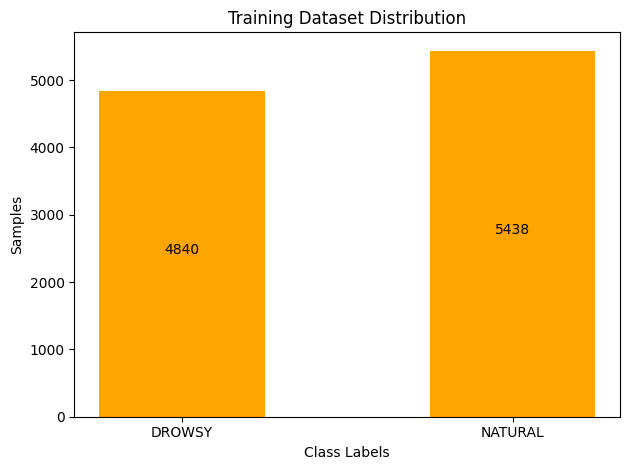

In [6]:
bar = plt.bar(class_names, height=class_samples, width=0.5, color='orange')
plt.bar_label(bar, label_type='center', padding=3)
plt.xlabel('Class Labels')
plt.ylabel('Samples')
plt.title('Training Dataset Distribution')
plt.tight_layout()
plt.show()

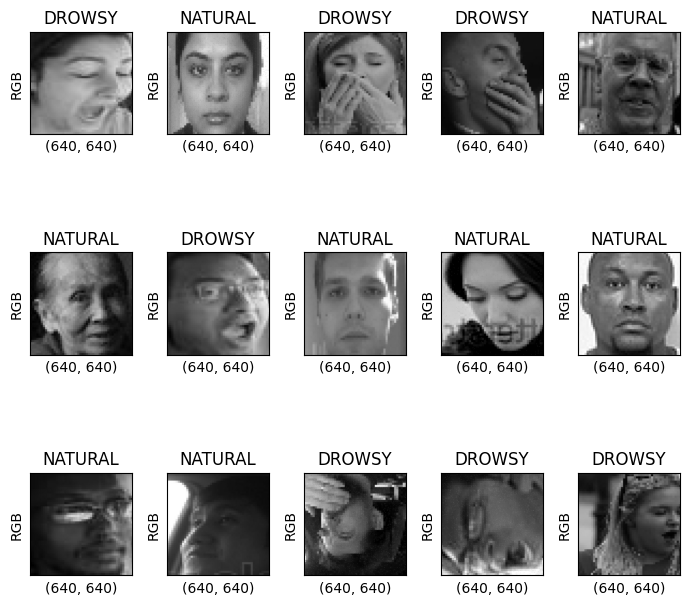

In [7]:
# Training Images Dimension

fig = plt.figure(figsize=(7, 7))
rows, columns = 3, 5

for i in range(1, rows*columns+1):
    
    fig.add_subplot(rows, columns, i)
    
    random_idx = torch.randint(0, len(train_data), size=(1,)).item()
    image, label = train_data[random_idx]
    
    plt.imshow(image)
    plt.title(class_names[label])
    plt.ylabel(image.mode)
    plt.xlabel(image.size)
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

### Data Preprocessing & Augmentation

Training Data Mean and Std

In [8]:
train_data_stats = DataLoader(ImageFolder(root=train_data.root, transform=transforms.ToTensor()), batch_size=128, num_workers=6, pin_memory=(device.type == 'cuda'), shuffle=False)

channel_sum = torch.zeros(3, device=device)
channel_sum_sq = torch.zeros(3, device=device)
total_batches = 0
total_pixels = 0

for data, lbl in train_data_stats:
    data = data.to(device, non_blocking=True)
    channel_sum += torch.sum(data, dim=[0,2,3])
    channel_sum_sq += torch.sum(data**2, dim=[0,2,3])
    total_pixels += data.shape[0] * data.shape[2] * data.shape[3]
    total_batches +=1

mean = channel_sum / total_pixels
meansq = channel_sum_sq / total_pixels
variance = meansq - mean**2
std = torch.sqrt(variance.clamp_min(0))

print(f'Dataset Mean: {mean} and Std: {std}')
print(f'Total Batches Processed: {total_batches}')

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 6 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 6 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Dataset Mean: tensor([0.4373, 0.4373, 0.4373], device='cuda:0') and Std: tensor([0.2483, 0.2483, 0.2483], device='cuda:0')
Total Batches Processed: 81


In [9]:
mean = [0.4373, 0.4373, 0.4373]
std = [0.2483, 0.2483, 0.2483]
batches_process = 81
total_pixels = 4209868800

Train Transformation & Augmentation

### Model Architecture Design

### Model Training Pipeline

### Evaluation & Hyperparameter Tunning

### Model Inference Pipeline

### Model Deployment MLOps